In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [2]:
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [4]:
job_titles = df['job_title_short'].unique().tolist()

In [61]:
df_skills = df.copy()
df_skills = df_skills.explode('job_skills')
skills_count = df_skills.groupby(['job_title_short', 'job_skills']).size().reset_index(name='count')
df_skills_count = skills_count


In [65]:
df_skills_count

,job_title_short,job_skills,count
0,Business Analyst,airflow,318
1,Business Analyst,airtable,17
2,Business Analyst,alteryx,1078
3,Business Analyst,angular,87
4,Business Analyst,ansible,120
...,...,...,...
2251,Software Engineer,wrike,4
2252,Software Engineer,wsl,13
2253,Software Engineer,xamarin,35
2254,Software Engineer,yarn,145


In [39]:
top_jobs =df['job_title_short'].value_counts().nlargest(3).index.tolist()

In [40]:
top_jobs

['Data Analyst', 'Data Engineer', 'Data Scientist']

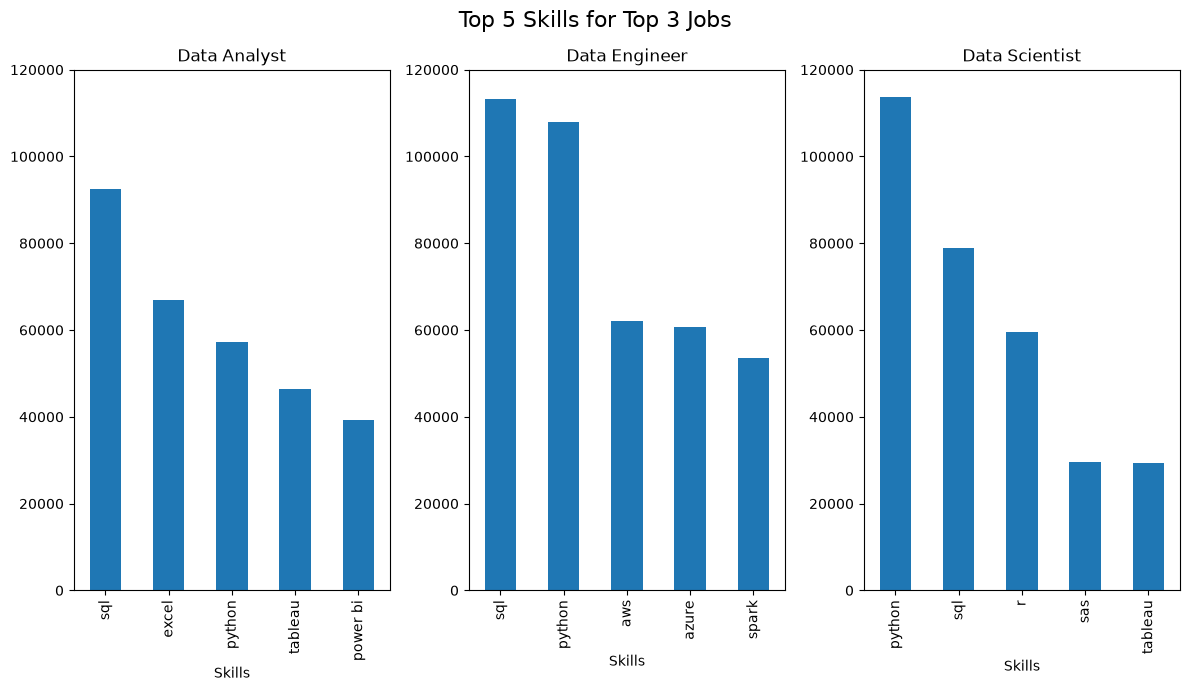

In [89]:
fig , ax = plt.subplots(1, 3 , figsize=(12,7))

for i, job in enumerate(top_jobs):
    top_skills = df_skills_count[df_skills_count['job_title_short'] == job].nlargest(5, 'count')
    top_skills.plot(kind='bar', x='job_skills', y='count', ax=ax[i], title=job, legend=False)
    ax[i].set_xlabel('Skills')
    ax[i].set_ylabel('')
    ax[i].set_ylim(0, 120000)
    
fig.suptitle(f'Top {len(top_skills)} Skills for Top {len(top_jobs)} Jobs', fontsize=16)
fig.tight_layout()